**GROUP 8**

Campus Service Queue Prioritization *(Decision Support / Scheduling)*

Scenario: A campus service office wants to organize its queue using arrival time, urgency, service type, and expected service duration.

**Import libraries.**

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

**Upload datasets.**

*Upload sequence:*
1) student_service_priority.csv
2) student_service_priority copy.csv



In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload the original complete dataset.
original_upload = files.upload()
original_file = next(iter(original_upload))
original = pd.read_csv(original_file)

# Upload the copied dataset with missing values.
missing_upload = files.upload()
missing_file = next(iter(missing_upload))
missing = pd.read_csv(missing_file)

print("Original dataset:", original.shape)
print("Missing-value dataset:", missing.shape)


Saving student_service_priority.csv to student_service_priority (6).csv


Saving student_service_priority copy.csv to student_service_priority copy (5).csv
Original dataset: (100, 8)
Missing-value dataset: (100, 8)


**Check datasets**

In [36]:
print("Missing values in the original dataset:")
print(original.isna().sum())

print("Missing values in the copy dataset:")
print(missing.isna().sum())

print("\nDuplicate record IDs:", original["record_id"].duplicated().sum())
print("Duration range:", original["estimated_duration"].min(), "to", original["estimated_duration"].max())


Missing values in the original dataset:
record_id             0
arrival_time          0
service_type          0
urgency               0
estimated_duration    0
student_type          0
document_complete     0
special_assistance    0
dtype: int64
Missing values in the copy dataset:
record_id             0
arrival_time          2
service_type          2
urgency               3
estimated_duration    1
student_type          2
document_complete     1
special_assistance    1
dtype: int64

Duplicate record IDs: 0
Duration range: 5 to 60


**Define priority rules.**

In [37]:
urgency_points = {"High": 40, "Medium": 25, "Low": 10}

Scoring rules:
- High urgency = 40 points
- Medium urgency = 25 points
- Low urgency = 10 points
- Graduating student = 25 points
- Non-Graduating student = 10 points
- Special assistance = 20 points
- Incomplete documents = -10 points
- Estimated duration of 15 minutes or less = 5 points

**Calculate priority scores.**

In [38]:
def score_records(data):
    df = data.copy()
    df["arrival_time"] = pd.to_datetime(df["arrival_time"], errors="coerce")
    df["estimated_duration"] = pd.to_numeric(df["estimated_duration"], errors="coerce")

    df["urgency"] = df["urgency"].fillna("Low")
    df["service_type"] = df["service_type"].fillna("General Inquiry")
    df["student_type"] = df["student_type"].fillna("Non-Graduating")
    df["document_complete"] = df["document_complete"].fillna("No")
    df["special_assistance"] = df["special_assistance"].fillna("No")
    df["estimated_duration"] = df["estimated_duration"].fillna(
        df["estimated_duration"].median()
    )

    df["priority_score"] = (
        df["urgency"].map(urgency_points).fillna(0)
        + np.where(df["student_type"] == "Graduating", 25, 10)
        + np.where(df["special_assistance"] == "Yes", 20, 0)
        + np.where(df["document_complete"] == "No", -10, 0)
        + np.where(df["estimated_duration"] <= 15, 5, 0)
    )
    return df

scored = score_records(original)

**Generate the two queue orders.**

In [39]:
priority_order = scored.sort_values(
    ["priority_score", "arrival_time", "record_id"],
    ascending=[False, True, True],
    na_position="last"
).reset_index(drop=True)
priority_order.insert(0, "priority_rank", range(1, len(priority_order) + 1))

fifo_order = scored.sort_values(
    ["arrival_time", "record_id"],
    na_position="last"
).reset_index(drop=True)
fifo_order.insert(0, "fifo_rank", range(1, len(fifo_order) + 1))

print("Priority Scoring top 10:")
display(priority_order.head(10))

print("FIFO top 10:")
display(fifo_order.head(10))


Priority Scoring top 10:


,priority_rank,record_id,arrival_time,service_type,urgency,estimated_duration,student_type,document_complete,special_assistance,priority_score
0,1,1,2026-10-03 13:27:00,Enrollment,High,22,Graduating,Yes,Yes,85
1,2,29,2026-10-03 09:57:00,Scholarship,High,9,Non-Graduating,Yes,Yes,75
2,3,71,2026-10-03 09:26:00,Clearance,High,37,Non-Graduating,Yes,Yes,70
3,4,5,2026-10-03 10:22:00,Registrar,High,53,Non-Graduating,Yes,Yes,70
4,5,10,2026-10-03 11:09:00,Financial Aid,High,22,Non-Graduating,Yes,Yes,70
5,6,54,2026-10-03 12:58:00,Scholarship,High,13,Graduating,Yes,No,70
6,7,33,2026-10-03 13:34:00,Clearance,High,30,Non-Graduating,Yes,Yes,70
7,8,74,2026-10-03 14:07:00,Clearance,Medium,30,Graduating,Yes,Yes,70
8,9,6,2026-10-03 15:13:00,Financial Aid,Medium,56,Graduating,Yes,Yes,70
9,10,81,2026-10-03 15:37:00,Scholarship,High,14,Graduating,Yes,No,70


FIFO top 10:


,fifo_rank,record_id,arrival_time,service_type,urgency,estimated_duration,student_type,document_complete,special_assistance,priority_score
0,1,69,2026-10-03 08:00:00,Financial Aid,Medium,32,Non-Graduating,Yes,No,35
1,2,84,2026-10-03 08:03:00,Financial Aid,Medium,29,Non-Graduating,No,No,25
2,3,53,2026-10-03 08:04:00,Enrollment,High,49,Non-Graduating,Yes,No,50
3,4,19,2026-10-03 08:05:00,Clearance,Low,48,Non-Graduating,Yes,No,20
4,5,88,2026-10-03 08:13:00,Enrollment,Medium,13,Non-Graduating,Yes,No,40
5,6,30,2026-10-03 08:16:00,Financial Aid,High,20,Graduating,Yes,No,65
6,7,76,2026-10-03 08:25:00,Scholarship,High,59,Graduating,Yes,No,65
7,8,40,2026-10-03 08:31:00,Clearance,Medium,8,Non-Graduating,Yes,No,40
8,9,18,2026-10-03 08:32:00,Document Request,Medium,34,Non-Graduating,No,No,25
9,10,82,2026-10-03 08:32:00,Document Request,Medium,39,Non-Graduating,Yes,No,35


**Compare Priority Scoring and FIFO.**

In [40]:
comparison = priority_order[["record_id", "priority_rank", "priority_score"]].merge(
    fifo_order[["record_id", "fifo_rank"]],
    on="record_id"
)

comparison["rank_difference"] = (
    comparison["fifo_rank"] - comparison["priority_rank"]
)

top10 = comparison.sort_values("priority_rank").head(10)
display(top10)


,record_id,priority_rank,priority_score,fifo_rank,rank_difference
0,1,1,85,61,60
1,29,2,75,25,23
2,71,3,70,20,17
3,5,4,70,28,24
4,10,5,70,34,29
5,54,6,70,54,48
6,33,7,70,65,58
7,74,8,70,70,62
8,6,9,70,86,77
9,81,10,70,92,82


**Comparison chart**

The chart compares the ranks assigned by Priority Scoring and FIFO. Priority Scoring placed records such as 1, 29, and 71 near the top because they received higher priority scores. However, FIFO ranked these records lower because it only considered arrival time. This shows that the two algorithms produce different service orders.

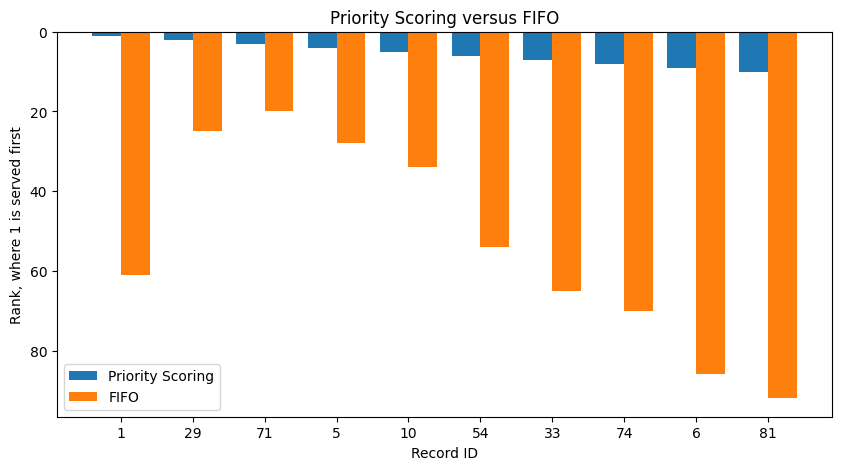

In [41]:
x = np.arange(len(top10))
width = 0.4

plt.figure(figsize=(10, 5))
plt.bar(x - width / 2, top10["priority_rank"], width, label="Priority Scoring")
plt.bar(x + width / 2, top10["fifo_rank"], width, label="FIFO")
plt.xticks(x, top10["record_id"].astype(str))
plt.gca().invert_yaxis()
plt.xlabel("Record ID")
plt.ylabel("Rank, where 1 is served first")
plt.title("Priority Scoring versus FIFO")
plt.legend()
plt.savefig("priority_vs_fifo_chart.png", dpi=200)
plt.show()


**Test missing, boundary, and uncertain cases**

In [42]:
# Missing-value test using the copied dataset.
missing_result = score_records(missing)
print("Missing values before handling:")
print(missing.isna().sum())
print("\nMissing-value test completed.")
display(missing_result.head())

# Boundary test for the 15-minute rule.
boundary = pd.DataFrame({"estimated_duration": [14, 15, 16]})
boundary["duration_score"] = np.where(
    boundary["estimated_duration"] <= 15, 5, 0
)
print("Boundary test:")
display(boundary)

# Uncertain case: records with the same score are ordered by arrival time.
same_score = priority_order[
    priority_order.duplicated("priority_score", keep=False)
]
print("Equal-score test:")
display(same_score[["record_id", "arrival_time", "priority_score", "priority_rank"]].head())


Missing values before handling:
record_id             0
arrival_time          2
service_type          2
urgency               3
estimated_duration    1
student_type          2
document_complete     1
special_assistance    1
dtype: int64

Missing-value test completed.


,record_id,arrival_time,service_type,urgency,estimated_duration,student_type,document_complete,special_assistance,priority_score
0,1,2026-10-03 13:27:00,Enrollment,High,22.0,Graduating,Yes,Yes,85
1,2,2026-10-03 14:19:00,Scholarship,High,32.0,Graduating,Yes,No,65
2,3,2026-10-03 13:08:00,Enrollment,Medium,50.0,Non-Graduating,Yes,No,35
3,4,2026-10-03 13:01:00,Financial Aid,Low,5.0,Non-Graduating,No,No,15
4,5,2026-10-03 10:22:00,Registrar,High,53.0,Non-Graduating,Yes,Yes,70


Boundary test:


,estimated_duration,duration_score
0,14,5
1,15,5
2,16,0


Equal-score test:


,record_id,arrival_time,priority_score,priority_rank
2,71,2026-10-03 09:26:00,70,3
3,5,2026-10-03 10:22:00,70,4
4,10,2026-10-03 11:09:00,70,5
5,54,2026-10-03 12:58:00,70,6
6,33,2026-10-03 13:34:00,70,7


**Interpretation and limitations**

Priority Scoring produced a different order from FIFO because it considers urgency, student type, special assistance, document completeness, and service duration. FIFO only considers arrival time. Therefore, Priority Scoring can place urgent or special cases earlier in the queue.

The weights were manually assigned and may not represent every campus situation. The results also depend on accurate input data. The system should support staff decisions rather than completely replace human judgment.

In [44]:
import os
import zipfile
from google.colab import files

output_files = [
    "priority_scoring_results.csv",
    "fifo_results.csv",
    "algorithm_comparison_all_records.csv",
    "algorithm_comparison_top10.csv",
    "missing_value_test_results.csv",
    "boundary_test_results.csv"
]

# Check that the files exist
for filename in output_files:
    print(filename, "exists:", os.path.exists(filename))

# Put all output files into one ZIP file
with zipfile.ZipFile(
    "CampusServiceQueuePrioritization.zip",
    "w"
) as zip_file:

    for filename in output_files:
        zip_file.write(filename)

print("Output files created successfully.")

# Download the ZIP file
files.download("CampusServiceQueuePrioritization.zip")

priority_scoring_results.csv exists: True
fifo_results.csv exists: True
algorithm_comparison_all_records.csv exists: True
algorithm_comparison_top10.csv exists: True
missing_value_test_results.csv exists: True
boundary_test_results.csv exists: True
Output files created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>